In [3]:
# RNN (LSTM) - Sequence Prediction
# Dataset: Airline Passengers - ../Datasets/AirPassengers.csv
# (same dataset as the classical time series script - good for comparing
#  "classical" SARIMA/Holt-Winters vs a neural network approach to the same problem)
#
# Needs: pip install tensorflow

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers


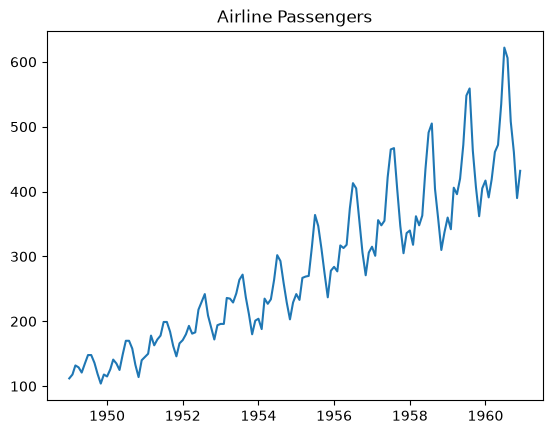

In [6]:
tf.random.set_seed(42)
np.random.seed(42)
#"C:\My-Data-Science-Portfolio\Datasets\AirPassengers.csv"
df = pd.read_csv(r"C:\My-Data-Science-Portfolio\Datasets\AirPassengers.csv")
#df = pd.read_csv("../Datasets/AirPassengers.csv")
df["Month"] = pd.to_datetime(df["Month"])
df = df.set_index("Month")
df = df.rename(columns={"#Passengers": "Passengers"})

series = df["Passengers"].values.reshape(-1, 1).astype(float)

plt.plot(df.index, series)
plt.title("Airline Passengers")
plt.show()

In [7]:
# ---- 1. Scale to 0-1 ----
# LSTMs (like most neural nets) train much better when inputs are small and
# consistently scaled - raw passenger counts (100-600) would work badly here
scaler = MinMaxScaler()
series_scaled = scaler.fit_transform(series)

# ---- 2. Chronological train/test split ----
# last 24 months held out, same as the classical time series script
train_size = len(series_scaled) - 24
train_data = series_scaled[:train_size]
test_data = series_scaled[train_size - 12:]   # include 12 months of lookback context


In [8]:
# ---- 3. Build sequences ----
# an RNN needs: "given the last N months, predict the next month"
# this turns the flat series into (input_sequence, next_value) pairs
def create_sequences(data, lookback=12):
    X, y = [], []
    for i in range(lookback, len(data)):
        X.append(data[i - lookback:i, 0])
        y.append(data[i, 0])
    return np.array(X), np.array(y)

LOOKBACK = 12   # use the past 12 months to predict the next one

X_train, y_train = create_sequences(train_data, LOOKBACK)
X_test, y_test = create_sequences(test_data, LOOKBACK)

# LSTM expects shape: (samples, timesteps, features)
X_train = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_test = X_test.reshape(X_test.shape[0], X_test.shape[1], 1)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)


X_train shape: (108, 12, 1)
X_test shape: (24, 12, 1)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                          │ (None, 12, 50)              │          10,400 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_1 (LSTM)                        │ (None, 50)                  │          20,200 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 1)                   │              51 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 30,651 (119.73 KB)

 Trainable params: 30,651 (119.73 KB)

 Non-trainable params: 0 (0.00 B)

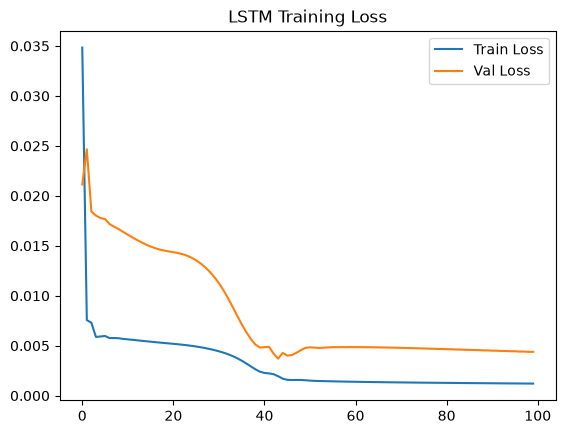

In [9]:
# ---- 4. Build the LSTM model ----
# LSTM = Long Short-Term Memory, a type of RNN designed to remember patterns
# over longer sequences better than a plain/vanilla RNN can
model = keras.Sequential([
    layers.Input(shape=(LOOKBACK, 1)),
    layers.LSTM(50, activation="tanh", return_sequences=True),
    layers.LSTM(50, activation="tanh"),
    layers.Dense(1)   # single numeric output - next month's (scaled) passengers
])

model.summary()

model.compile(optimizer="adam", loss="mse")

# ---- 5. Train ----
history = model.fit(
    X_train, y_train,
    epochs=100,
    batch_size=8,
    validation_split=0.1,
    verbose=0
)

plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Val Loss")
plt.title("LSTM Training Loss")
plt.legend()
plt.show()


In [10]:
# ---- 6. Predict on the test set ----
y_pred_scaled = model.predict(X_test, verbose=0)

# ---- 7. Convert predictions back to real passenger numbers ----
y_pred = scaler.inverse_transform(y_pred_scaled)
y_test_actual = scaler.inverse_transform(y_test.reshape(-1, 1))

mae = mean_absolute_error(y_test_actual, y_pred)
rmse = np.sqrt(mean_squared_error(y_test_actual, y_pred))
print(f"\nLSTM  MAE: {mae:.2f}   RMSE: {rmse:.2f}")

# compare this to the SARIMA/Holt-Winters results from the classical time
# series script - on a small dataset like this, classical methods often
# match or beat an LSTM, since LSTMs usually need a LOT more data to shine


LSTM  MAE: 36.70   RMSE: 47.76


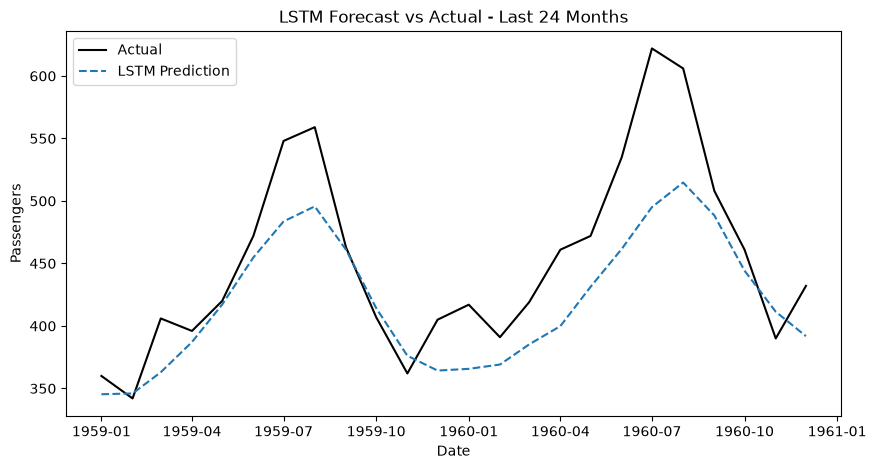

In [11]:
# ---- 8. Plot predictions vs actual ----
test_dates = df.index[-24:]

plt.figure(figsize=(10, 5))
plt.plot(test_dates, y_test_actual, label="Actual", color="black")
plt.plot(test_dates, y_pred, label="LSTM Prediction", linestyle="--")
plt.title("LSTM Forecast vs Actual - Last 24 Months")
plt.xlabel("Date")
plt.ylabel("Passengers")
plt.legend()
plt.show()

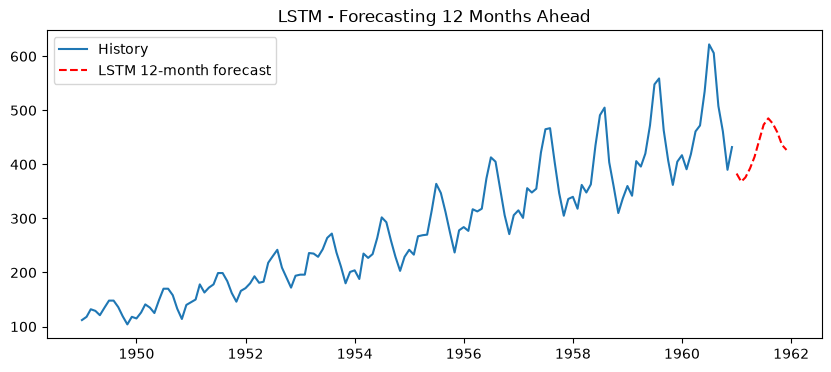

1961-01-01    383.0
1961-02-01    368.0
1961-03-01    376.0
1961-04-01    393.0
1961-05-01    414.0
1961-06-01    444.0
1961-07-01    473.0
1961-08-01    485.0
1961-09-01    475.0
1961-10-01    459.0
1961-11-01    436.0
1961-12-01    427.0
Freq: MS, dtype: float32


In [12]:
# ---- 9. Forecast further into the future (iteratively) ----
# to predict beyond the data we have, feed each prediction back in as input
# for the next step - this is how RNNs generate multi-step forecasts
last_sequence = series_scaled[-LOOKBACK:].reshape(1, LOOKBACK, 1)
future_predictions_scaled = []

current_seq = last_sequence.copy()
for _ in range(12):
    next_pred = model.predict(current_seq, verbose=0)
    future_predictions_scaled.append(next_pred[0, 0])
    # drop the oldest timestep, append the new prediction
    current_seq = np.append(current_seq[:, 1:, :], [[next_pred[0]]], axis=1)

future_predictions = scaler.inverse_transform(
    np.array(future_predictions_scaled).reshape(-1, 1)
)

future_dates = pd.date_range(df.index[-1] + pd.DateOffset(months=1), periods=12, freq="MS")

plt.figure(figsize=(10, 4))
plt.plot(df.index, df["Passengers"], label="History")
plt.plot(future_dates, future_predictions, label="LSTM 12-month forecast", linestyle="--", color="red")
plt.title("LSTM - Forecasting 12 Months Ahead")
plt.legend()
plt.show()

print(pd.Series(future_predictions.flatten(), index=future_dates).round(0))